# AgentAccess

**Authors:** Alexander Michels

In [1]:
import json
import os

In [2]:
# COMMENT THIS OUT WHEN RUNNING WITH THE SCRIPT
os.environ["costFunc"] = "raam"
os.environ["popPerAgent"] = "1000"
os.environ["timeStep"] = "10"
os.environ["myK"] = "1"

In [3]:
# FETCH THE VARS FROM THE ENVIRONMENT
envVariables = ["costFunc", "popPerAgent", "timeStep", "myK"]
paramDict = {}
for var in envVariables:
    paramDict[var] = os.getenv(var)

In [4]:
int_vars = ["popPerAgent", "timeStep", "myK"]
for iv in int_vars:
    paramDict[iv] = int(paramDict[iv])

In [5]:
print(json.dumps(paramDict, sort_keys=True, indent=True))

{
 "costFunc": "raam",
 "myK": 1,
 "popPerAgent": 1000,
 "timeStep": 10
}


In [6]:
import access
import geopandas as gpd
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
from tqdm import tqdm
import sys
sys.path.append("../")
from agentaccess.Model import AgentAccess
# pandas gives warnings too often
pd.options.mode.chained_assignment = None

In [7]:
figsize=(10,10)

## Load the Data

In [8]:
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [9]:
pop["vehicle"] = pop["E_TOTPOP"] - pop["E_NOVEH"]

In [10]:
for x in pop["vehicle"]:
    assert x >= 0

In [11]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
print(sum(hos["BEDS"]))
hos = hos.to_crs("EPSG:4326")
print(len(hos))
hos.head()

18259
66


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.89140)


<Axes: >

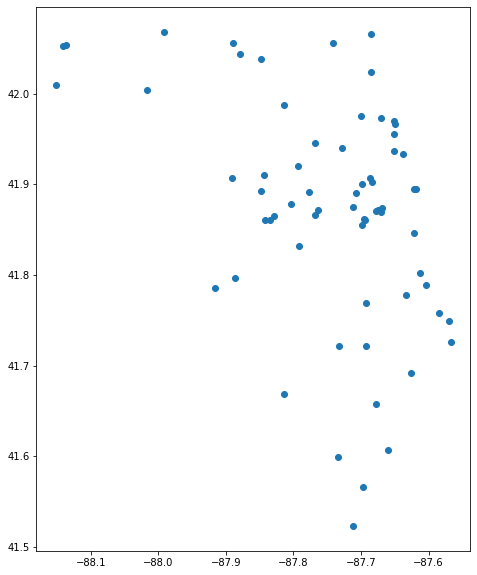

In [12]:
hos.plot(figsize=figsize)

In [13]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car = car.rename(columns={"minutes": "car"})
print(len(car))
car.head()

3780024


,origin,destination,car
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [14]:
# get the transit/walking times
transit = pd.read_csv("../data/travel_times/17031-output-TRACT-TRANSIT,WALK.csv")
transit["origin"] = transit["origin"].astype(str)
transit["destination"] = transit["destination"].astype(str)
transit = transit.rename(columns={"minutes": "transit"})
print(len(transit))
transit.head()

2853575


,origin,destination,transit
0,17031010100,17007010100,541.58
1,17031010100,17007010200,542.43
2,17031010100,17007010300,561.87
3,17031010100,17007010400,567.78
4,17031010100,17007010500,534.08


In [15]:
# get the walking times
walk = pd.read_csv("../data/travel_times/17031-output-TRACT-WALK.csv")
walk["origin"] = walk["origin"].astype(str)
walk["destination"] = walk["destination"].astype(str)
walk = walk.rename(columns={"minutes": "walk"})
print(len(walk))
walk.head()

234772


,origin,destination,walk
0,17031010100,17031010100,0.17
1,17031010100,17031010201,19.35
2,17031010100,17031010202,10.35
3,17031010100,17031010300,10.83
4,17031010100,17031010400,29.22


In [16]:
travel_times = pd.merge(car, transit, how="outer",
                       left_on=["origin", "destination"],
                       right_on=["origin", "destination"])
print(len(travel_times))
travel_times.head()

3782602


,origin,destination,car,transit
0,17031010100,17007010100,101.35,541.58
1,17031010100,17007010200,96.10,542.43
2,17031010100,17007010300,96.43,561.87
3,17031010100,17007010400,96.17,567.78
4,17031010100,17007010500,107.13,534.08


In [17]:
travel_times = pd.merge(travel_times, walk, how="outer",
                       left_on=["origin", "destination"],
                       right_on=["origin", "destination"])
print(len(travel_times))
travel_times.head()

3782602


,origin,destination,car,transit,walk
0,17031010100,17007010100,101.35,541.58,NaN
1,17031010100,17007010200,96.10,542.43,NaN
2,17031010100,17007010300,96.43,561.87,NaN
3,17031010100,17007010400,96.17,567.78,NaN
4,17031010100,17007010500,107.13,534.08,NaN


In [18]:
print(json.dumps(paramDict, sort_keys=True, indent=True))

{
 "costFunc": "raam",
 "myK": 1,
 "popPerAgent": 1000,
 "timeStep": 10
}


In [19]:
# intialize our model
# def __init__(self, demand_df, demand_geoid, demand_field, supply_df, supply_geoid, supply_field,
#              cost_df, cost_origin, cost_dest, cost_field, time_steps, memory=0, pop_per_agent=1000, top_k=0):
for i in range(1):
    random.seed(i)
    model = AgentAccess(
        pop,
        "FIPS",
        "E_TOTPOP",
        hos,
        "who cares",
        "BEDS",
        travel_times,
        "origin",
        "destination",
        ["car", "transit"],
        paramDict["timeStep"],
        cost_function=paramDict["costFunc"],
    #     cost_prop=[0.7, 0.2, 0.1],
        cost_prop_fields=["vehicle", "E_NOVEH"],
        memory=0,
        pop_per_agent=paramDict["popPerAgent"],
        top_k=paramDict["myK"],
        output_path="../outputs",
        plot=False,
        save_data=False
    )
    model.run_model()

Running Model: 100%|██████████████████████████████████████████████| 10/10 [09:51<00:00, 59.18s/it]


In [20]:
def average_columns(df, new_column, columns_to_average):
    df[new_column] = df[columns_to_average].mean(axis=1)
    return df

In [21]:
# calculate averages for columns
ts = paramDict["timeStep"]
portions = [2, 3, 4]
cols_to_average = ["Cost", "Time", "D/S Ratio"]
cols_to_save = []
df = model.spatial_units_df
for port in portions:
    for col in cols_to_average:
        cols_to_save.append(f"{col}_{port}")
        # average the last 1/port time steps
        df = average_columns(df, f"{col}_{port}", [f"{col} {x}" for x  in range(ts-(ts//port), ts)])
df = df[cols_to_save]

In [22]:
df.head()

,Cost_2,Time_2,D/S Ratio_2,Cost_3,Time_3,D/S Ratio_3,Cost_4,Time_4,D/S Ratio_4
GEOID,,,,,,,,,
17031381700,1.855464,12.382,0.814107,1.864972,11.37,0.444529,1.866239,10.730,0.320000
17031980000,1.723936,29.390,0.338222,1.764752,31.47,0.257754,1.773542,31.470,0.259893
17031980100,1.603400,21.510,0.747071,1.646339,20.71,0.483206,1.650624,21.875,0.378015
17031020100,1.147907,4.850,0.405738,1.201797,4.85,0.379781,1.203275,4.850,0.409836
17031020200,1.222907,7.100,0.405738,1.276797,7.10,0.379781,1.278275,7.100,0.409836


In [23]:
df.to_csv(os.path.join(model.output_dir, "spatial_units.csv"))